## importing data

In [5]:
import pandas as pd

train = pd.read_csv("train.csv")  
test = pd.read_csv("test.csv")
train.head()
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   Class Index  120000 non-null  int64
 1   Title        120000 non-null  str  
 2   Description  120000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 2.7 MB


In [6]:
train['text'] = train['Title'] + " " + train['Description']
test['text'] = test['Title'] + " " + test['Description']
train = train[['text', 'Class Index']]
test = test[['text', 'Class Index']]

## Text Preprocessing

In [7]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)  # إزالة الرموز
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return " ".join(tokens)

train['clean_text'] = train['text'].apply(preprocess)
test['clean_text'] = test['text'].apply(preprocess)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Vectorization

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=10000)
X_train = vectorizer.fit_transform(train['clean_text'])
X_test = vectorizer.transform(test['clean_text'])

y_train = train['Class Index']
y_test = test['Class Index']

## Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

model = LogisticRegression(
    solver='lbfgs',          
    max_iter=1000,           
    random_state=42
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9132894736842105
              precision    recall  f1-score   support

           1       0.93      0.90      0.92      1900
           2       0.95      0.98      0.96      1900
           3       0.88      0.88      0.88      1900
           4       0.89      0.89      0.89      1900

    accuracy                           0.91      7600
   macro avg       0.91      0.91      0.91      7600
weighted avg       0.91      0.91      0.91      7600



## Visualization of frequent words per category

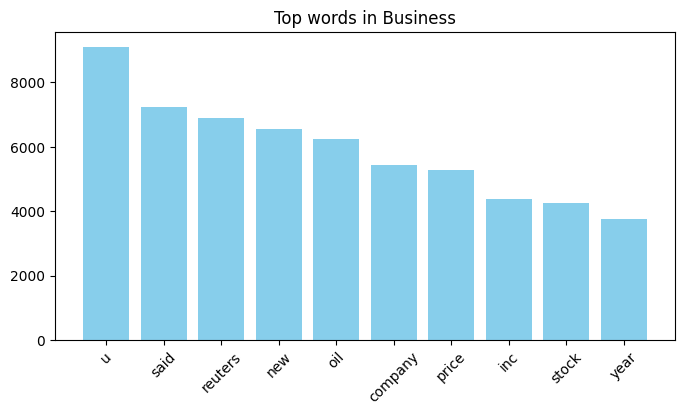

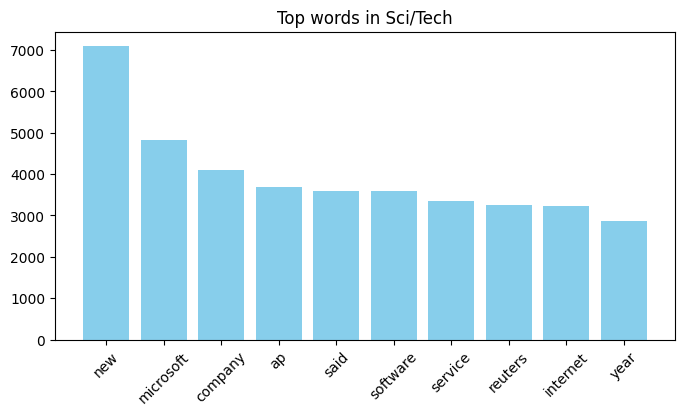

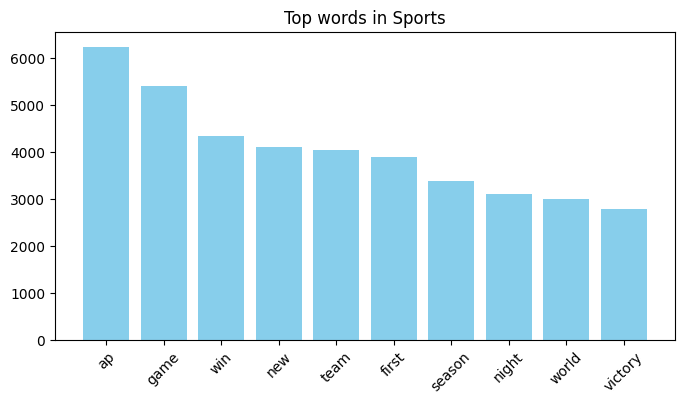

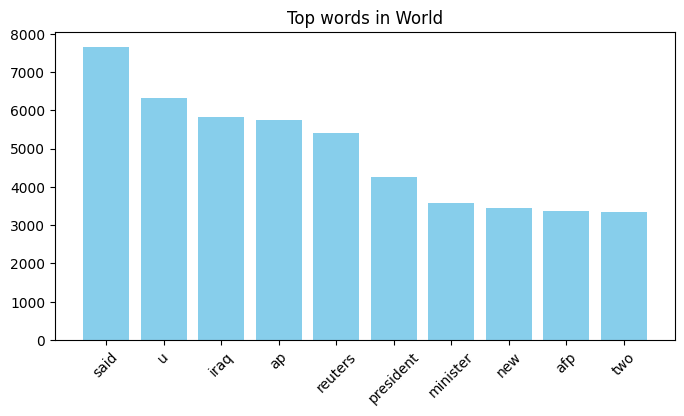

In [13]:
from collections import Counter
import matplotlib.pyplot as plt

# Map numeric class indices to category names
category_map = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}
train['Category_name'] = train['Class Index'].map(category_map)

# Plot the top 10 words per category
for cat in train['Category_name'].unique():
    words = " ".join(train[train['Category_name']==cat]['clean_text']).split()
    most_common = Counter(words).most_common(10)
    words_list, counts = zip(*most_common)
    
    plt.figure(figsize=(8,4))
    plt.bar(words_list, counts, color='skyblue')
    plt.title(f"Top words in {cat}")
    plt.xticks(rotation=45)
    plt.show()



## Neural Network



In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import numpy as np
from sklearn.metrics import classification_report

# Encode labels
le = LabelEncoder()
y_enc = le.fit_transform(y_train)
y_enc = to_categorical(y_enc)

input_dim = X_train.shape[1]

# Build model
model = Sequential()
model.add(Dense(512, activation='relu', input_dim=input_dim))
model.add(Dense(256, activation='relu'))
model.add(Dense(len(le.classes_), activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Convert sparse matrix to dense with less memory
X_train_dense = X_train.astype("float32").toarray()

# Train model
history = model.fit(
    X_train_dense,
    y_enc,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

# Show results
print("Final Training Accuracy:", history.history['accuracy'][-1])
print("Final Validation Accuracy:", history.history['val_accuracy'][-1])

# Predictions
pred = model.predict(X_train_dense)

pred_classes = np.argmax(pred, axis=1)
true_classes = np.argmax(y_enc, axis=1)

# Classification report
print(classification_report(true_classes, pred_classes))

d:\Data scince\Elevo NLP\nlp_env\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 265s 238ms/step - accuracy: 0.8996 - loss: 0.3061 - val_accuracy: 0.9084 - val_loss: 0.2554
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 141s 167ms/step - accuracy: 0.9384 - loss: 0.1734 - val_accuracy: 0.9068 - val_loss: 0.2737
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 101s 119ms/step - accuracy: 0.9609 - loss: 0.1070 - val_accuracy: 0.9080 - val_loss: 0.3298
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 106s 126ms/step - accuracy: 0.9804 - loss: 0.0534 - val_accuracy: 0.8988 - val_loss: 0.4288
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 120s 141ms/step - accuracy: 0.9898 - loss: 0.0288 - val_accuracy: 0.8980 - val_loss: 0.4995
Final Training Accuracy: 0.9897500276565552
Final Validation Accuracy: 0.8980000019073486
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 124s 21ms/step
              precision    recall  f1-score   support

           0       0.99      0.98      0.99     30000
           1       1.00      1.00      1.00     30000
           2       0.98      0.98      0.98   